<a href="https://colab.research.google.com/github/hsfcoulibaly/aml_project/blob/main/yolo_filament_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YOLO11-seg baseline — Solar Filament Segmentation 2026

Instance-segmentation baseline to compare against Sheikh's U-Net.

**Same protocol as the U-Net so the numbers are comparable:**
- same train/val split (`Sheikh/outputs/threshold_eval/grouped_split.json`, grouped by physical image → no leakage)
- every annotation record is its own sample (937 train / 217 val records)
- Dice and IoU computed per validation record on 512×512 binary masks, same formula as `evaluate_unet.py`

**Where to run:** Google Colab (*Runtime → Change runtime type → T4 GPU*) or a Kaggle notebook with *GPU T4* accelerator (and *Internet ON* in the settings panel), with the competition data added as input. It also runs locally (Apple MPS / CUDA / CPU) — set `DATA_ROOT` below.

**Time:** `QUICK = True` ≈ 30–45 min on a T4. `QUICK = False` ≈ 1.5–2.5 h.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "pycocotools"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'ultralytics', 'pycocotools'], returncode=0)

## 0. Colab only: download the competition data
Skipped automatically on Kaggle. On Colab you need your Kaggle API token: kaggle.com → *Settings* → *API* → **Create New Token**, copy the `KGAT_...` token, and paste it when the cell asks (the input is hidden and not saved in the notebook). You must also have clicked **Join Competition / accept the rules** on the competition page, otherwise the download returns 403.

In [2]:
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
COMPETITION = "filament-segmentation-2026"

if IN_COLAB and not Path("data").exists():
    kaggle_dir = Path.home() / ".kaggle"; kaggle_dir.mkdir(exist_ok=True)
    has_legacy = (kaggle_dir / "kaggle.json").exists()
    if not has_legacy and not os.environ.get("KAGGLE_API_TOKEN"):
        # New-style token (starts with KGAT_). Hidden input: it is NOT saved in the notebook.
        from getpass import getpass
        token = getpass("Paste your Kaggle API token (KGAT_...): ").strip()
        os.environ["KAGGLE_API_TOKEN"] = token
        (kaggle_dir / "access_token").write_text(token)
        os.chmod(kaggle_dir / "access_token", 0o600)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=True)
    subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", "data"], check=True)
    for z in Path("data").glob("*.zip"):
        zipfile.ZipFile(z).extractall("data"); z.unlink()
    print("Data ready:", sorted(p.name for p in Path("data").iterdir()))
elif IN_COLAB:
    print("data/ already present - skipping download")

Paste your Kaggle API token (KGAT_...): ··········
Data ready: ['MAGFiLO_1.0_Kaggle_2026']


## 1. Configuration

In [3]:
from pathlib import Path

QUICK = True            # True: fast first result. False: stronger, slower run.

MODEL   = "yolo11s-seg.pt" if QUICK else "yolo11m-seg.pt"
EPOCHS  = 30 if QUICK else 80
IMGSZ   = 1024          # 1024 keeps thin filaments better than 640; drop to 640 if out of memory
BATCH   = 8 if QUICK else 4
PATIENCE = 15
SEED    = 42

# Where the competition data lives. None = search /kaggle/input and ./data automatically.
DATA_ROOT = None

# The team's grouped split. Downloaded from GitHub; or put the file next to this notebook.
SPLIT_URL  = "https://raw.githubusercontent.com/hsfcoulibaly/aml_project/main/Sheikh/outputs/threshold_eval/grouped_split.json"
SPLIT_FILE = Path("grouped_split.json")

WORK = (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("yolo_work")).resolve()
WORK.mkdir(parents=True, exist_ok=True)
EVAL_SIZE = 512                       # matches the U-Net evaluation
CONF_THRESHOLDS = [0.1, 0.25, 0.4, 0.5]

## 2. Locate the data

In [4]:
import json, glob, os

def find_data(root=None):
    roots = [Path(root)] if root else [Path("/kaggle/input"), Path("data"), Path("../data"), Path(".")]
    for r in roots:
        if not r.exists():
            continue
        jsons = sorted(r.rglob("*MAGFiLO*train*.json")) or sorted(r.rglob("*train*.json"))
        if not jsons:
            continue
        ann = jsons[0]
        # image folder = the folder with the most .jpeg/.jpg files near the json
        candidates = {}
        for ext in ("*.jpeg", "*.jpg", "*.png"):
            for p in r.rglob(ext):
                if "test" in str(p.parent).lower():
                    continue
                candidates[p.parent] = candidates.get(p.parent, 0) + 1
        if candidates:
            img_dir = max(candidates, key=candidates.get)
            return ann, img_dir
    raise FileNotFoundError("Could not find the annotation JSON / images. Set DATA_ROOT.")

ANN_FILE, IMG_DIR = find_data(DATA_ROOT)
print("Annotations:", ANN_FILE)
print("Images     :", IMG_DIR, f"({len(list(IMG_DIR.glob('*')))} files)")

Annotations: data/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
Images     : data/MAGFiLO_1.0_Kaggle_2026/train/train_images (707 files)


## 3. Load annotations and the grouped split

In [5]:
from collections import defaultdict
import random, urllib.request

data = json.load(open(ANN_FILE))
anns_by_record = defaultdict(list)
for a in data["annotations"]:
    anns_by_record[a["image_id"]].append(a)
records = data["images"]          # one entry per annotation record (several per physical image)
print(f"{len(records)} records | {len({r['file_name'] for r in records})} physical images | {len(data['annotations'])} polygons")

if not SPLIT_FILE.exists():
    try:
        urllib.request.urlretrieve(SPLIT_URL, SPLIT_FILE)
        print("Downloaded split from GitHub")
    except Exception as e:
        print("Could not download split:", e)

if SPLIT_FILE.exists():
    split = json.load(open(SPLIT_FILE))
    train_files = set(split["train"]["file_names"]); val_files = set(split["val"]["file_names"])
else:
    # Fallback: same idea (80/20 by physical image, seed 42) but NOT guaranteed identical to the U-Net split.
    print("WARNING: using a regenerated split - results not strictly comparable with the U-Net")
    files = sorted({r["file_name"] for r in records}); random.Random(SEED).shuffle(files)
    n_val = round(0.2 * len(files)); val_files = set(files[:n_val]); train_files = set(files[n_val:])

assert train_files.isdisjoint(val_files)
train_recs = [r for r in records if r["file_name"] in train_files]
val_recs   = [r for r in records if r["file_name"] in val_files]
print(f"train: {len(train_files)} images / {len(train_recs)} records   val: {len(val_files)} images / {len(val_recs)} records")

1154 records | 707 physical images | 8199 polygons
Downloaded split from GitHub
train: 566 images / 937 records   val: 141 images / 217 records


## 4. Convert to YOLO segmentation format
One class (`filament`). Each annotation record becomes one sample: the image is linked under the record id and gets its own label file. Coordinates are normalised to [0, 1].

In [6]:
import shutil

DS = WORK / "yolo_ds"
if DS.exists():
    shutil.rmtree(DS)

def write_split(name, recs):
    (DS / "images" / name).mkdir(parents=True, exist_ok=True)
    (DS / "labels" / name).mkdir(parents=True, exist_ok=True)
    n_poly = 0
    for r in recs:
        src = (IMG_DIR / r["file_name"]).resolve()
        if not src.exists():
            print("missing image:", src); continue
        stem = str(r["id"])
        dst = DS / "images" / name / f"{stem}{src.suffix}"
        try:
            os.symlink(src, dst)
        except OSError:
            shutil.copy(src, dst)
        W, H = r["width"], r["height"]
        lines = []
        for a in anns_by_record.get(r["id"], []):
            seg = a.get("segmentation") or []
            if isinstance(seg, dict):      # RLE - not expected in this dataset
                continue
            for poly in seg:
                if len(poly) < 6:
                    continue
                xy = [min(max(v / (W if i % 2 == 0 else H), 0.0), 1.0) for i, v in enumerate(poly)]
                lines.append("0 " + " ".join(f"{v:.6f}" for v in xy))
                n_poly += 1
        (DS / "labels" / name / f"{stem}.txt").write_text("\n".join(lines))
    print(f"{name}: {len(recs)} samples, {n_poly} polygons")

write_split("train", train_recs)
write_split("val", val_recs)

yaml_path = DS / "filaments.yaml"
yaml_path.write_text(f"path: {DS.resolve()}\ntrain: images/train\nval: images/val\nnames:\n  0: filament\n")
print(yaml_path.read_text())

train: 937 samples, 6606 polygons
val: 217 samples, 1593 polygons
path: /content/yolo_work/yolo_ds
train: images/train
val: images/val
names:
  0: filament



## 5. Train
Augmentation suited to full-disk solar images: horizontal + vertical flips and rotations; colour jitter off (images are grayscale).

In [7]:
import torch
from ultralytics import YOLO

if torch.cuda.is_available():
    DEVICE = 0
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("device:", DEVICE)

model = YOLO(MODEL)
results = model.train(
    data=str(yaml_path), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, patience=PATIENCE,
    seed=SEED, deterministic=True, device=DEVICE, project=str(WORK / "runs"), name="yolo_seg",
    exist_ok=True, overlap_mask=False, mask_ratio=2,     # finer mask prototypes than default (4)
    fliplr=0.5, flipud=0.5, degrees=90, mosaic=0.5, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2,
    plots=True, verbose=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST = RUN_DIR / "weights" / "best.pt"
print("best weights:", BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
device: 0
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_work/yolo_ds/filaments.yaml, degrees=90, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchsc

## 6. Standard YOLO metrics (box and mask mAP)

In [8]:
best = YOLO(str(BEST))
m = best.val(data=str(yaml_path), imgsz=IMGSZ, batch=BATCH, device=DEVICE, split="val", plots=False)
yolo_metrics = {
    "box_mAP50": float(m.box.map50), "box_mAP50_95": float(m.box.map),
    "mask_mAP50": float(m.seg.map50), "mask_mAP50_95": float(m.seg.map),
    "mask_precision": float(m.seg.mp), "mask_recall": float(m.seg.mr),
}
print(json.dumps(yolo_metrics, indent=2))

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4928.7±941.0 MB/s, size: 771.8 KB)
val: Scanning /content/yolo_work/yolo_ds/labels/val.cache... 217 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 217/217 70.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 2.2it/s 12.7s
                   all        217       1593      0.622      0.677       0.67      0.392      0.626      0.638      0.659      0.234
Speed: 2.5ms preprocess, 42.6ms inference, 0.0ms loss, 3.6ms postprocess per image
{
  "box_mAP50": 0.669696971053243,
  "box_mAP50_95": 0.39239339545727414,
  "mask_mAP50": 0.6589295495410865,
  "mask_mAP50_95": 0.23369948431928034,
  "mask_precision": 0.6262633302681258,
  "mask_recall": 0.6384

## 7. Dice / IoU — same protocol as the U-Net
Ground truth is built exactly like `prepare_unet_data.py` (rasterise polygons at full resolution → resize to 512 with nearest neighbour). The YOLO instance masks are merged into one binary mask, resized the same way, and compared with the formula from `evaluate_unet.py`.

In [9]:
import cv2, numpy as np, pandas as pd
from pycocotools import mask as mask_utils

def gt_mask(rec):
    H, W = rec["height"], rec["width"]
    m = np.zeros((H, W), np.uint8)
    for a in anns_by_record.get(rec["id"], []):
        seg = a.get("segmentation") or []
        if not seg: continue
        dec = mask_utils.decode(mask_utils.frPyObjects(seg, H, W))
        if dec.ndim == 3: dec = dec.any(axis=2)
        m |= dec.astype(np.uint8)
    return cv2.resize(m, (EVAL_SIZE, EVAL_SIZE), interpolation=cv2.INTER_NEAREST)

def metrics(pred, target):            # identical to evaluate_unet.calculate_metrics
    pred = pred.astype(bool); target = target.astype(bool)
    inter = np.logical_and(pred, target).sum(); p = pred.sum(); t = target.sum()
    union = np.logical_or(pred, target).sum()
    if p + t == 0: return 1.0, 1.0, 0, 0
    return float(2 * inter / (p + t)), float(inter / union if union else 0.0), int(p), int(t)

# Predict once per physical image (all records of an image share the prediction), low conf to sweep thresholds.
pred_cache = {}
for fname in sorted(val_files):
    r = best.predict(str(IMG_DIR / fname), imgsz=IMGSZ, conf=min(CONF_THRESHOLDS), device=DEVICE,
                     retina_masks=True, verbose=False, max_det=300)[0]
    if r.masks is None:
        pred_cache[fname] = (np.zeros((0, EVAL_SIZE, EVAL_SIZE), np.uint8), np.zeros(0))
        continue
    ms = r.masks.data.cpu().numpy().astype(np.uint8)
    ms = np.stack([cv2.resize(x, (EVAL_SIZE, EVAL_SIZE), interpolation=cv2.INTER_NEAREST) for x in ms])
    pred_cache[fname] = (ms, r.boxes.conf.cpu().numpy())
print("predicted", len(pred_cache), "validation images")

rows = []
for rec in val_recs:
    target = gt_mask(rec)
    ms, confs = pred_cache[rec["file_name"]]
    for c in CONF_THRESHOLDS:
        keep = confs >= c
        pred = ms[keep].any(axis=0) if keep.any() else np.zeros((EVAL_SIZE, EVAL_SIZE), bool)
        d, i, p, t = metrics(pred, target)
        rows.append(dict(record=rec["id"], conf=c, dice=d, iou=i, predicted_pixels=p, target_pixels=t,
                         n_instances=int(keep.sum())))
df = pd.DataFrame(rows)
df.to_csv(WORK / "yolo_threshold_evaluation.csv", index=False)

summary = df.groupby("conf").agg(mean_dice=("dice", "mean"), median_dice=("dice", "median"),
                                 mean_iou=("iou", "mean"), mean_instances=("n_instances", "mean")).round(4)
print(f"YOLO ({MODEL}, imgsz {IMGSZ}) on {df.record.nunique()} validation records:")
print(summary.to_string())
print("\nReference - U-Net (Sheikh), threshold 0.5: mean Dice 0.6310 | median Dice 0.6591 | mean IoU 0.4709")

predicted 141 validation images
YOLO (yolo11s-seg.pt, imgsz 1024) on 217 validation records:
      mean_dice  median_dice  mean_iou  mean_instances
conf                                                  
0.10     0.6225       0.6506    0.4633         15.2396
0.25     0.6500       0.6697    0.4930          8.2028
0.40     0.5984       0.6363    0.4490          5.1659
0.50     0.5293       0.5833    0.3880          3.7143

Reference - U-Net (Sheikh), threshold 0.5: mean Dice 0.6310 | median Dice 0.6591 | mean IoU 0.4709


## 8. Visual check (same layout as the U-Net figure)

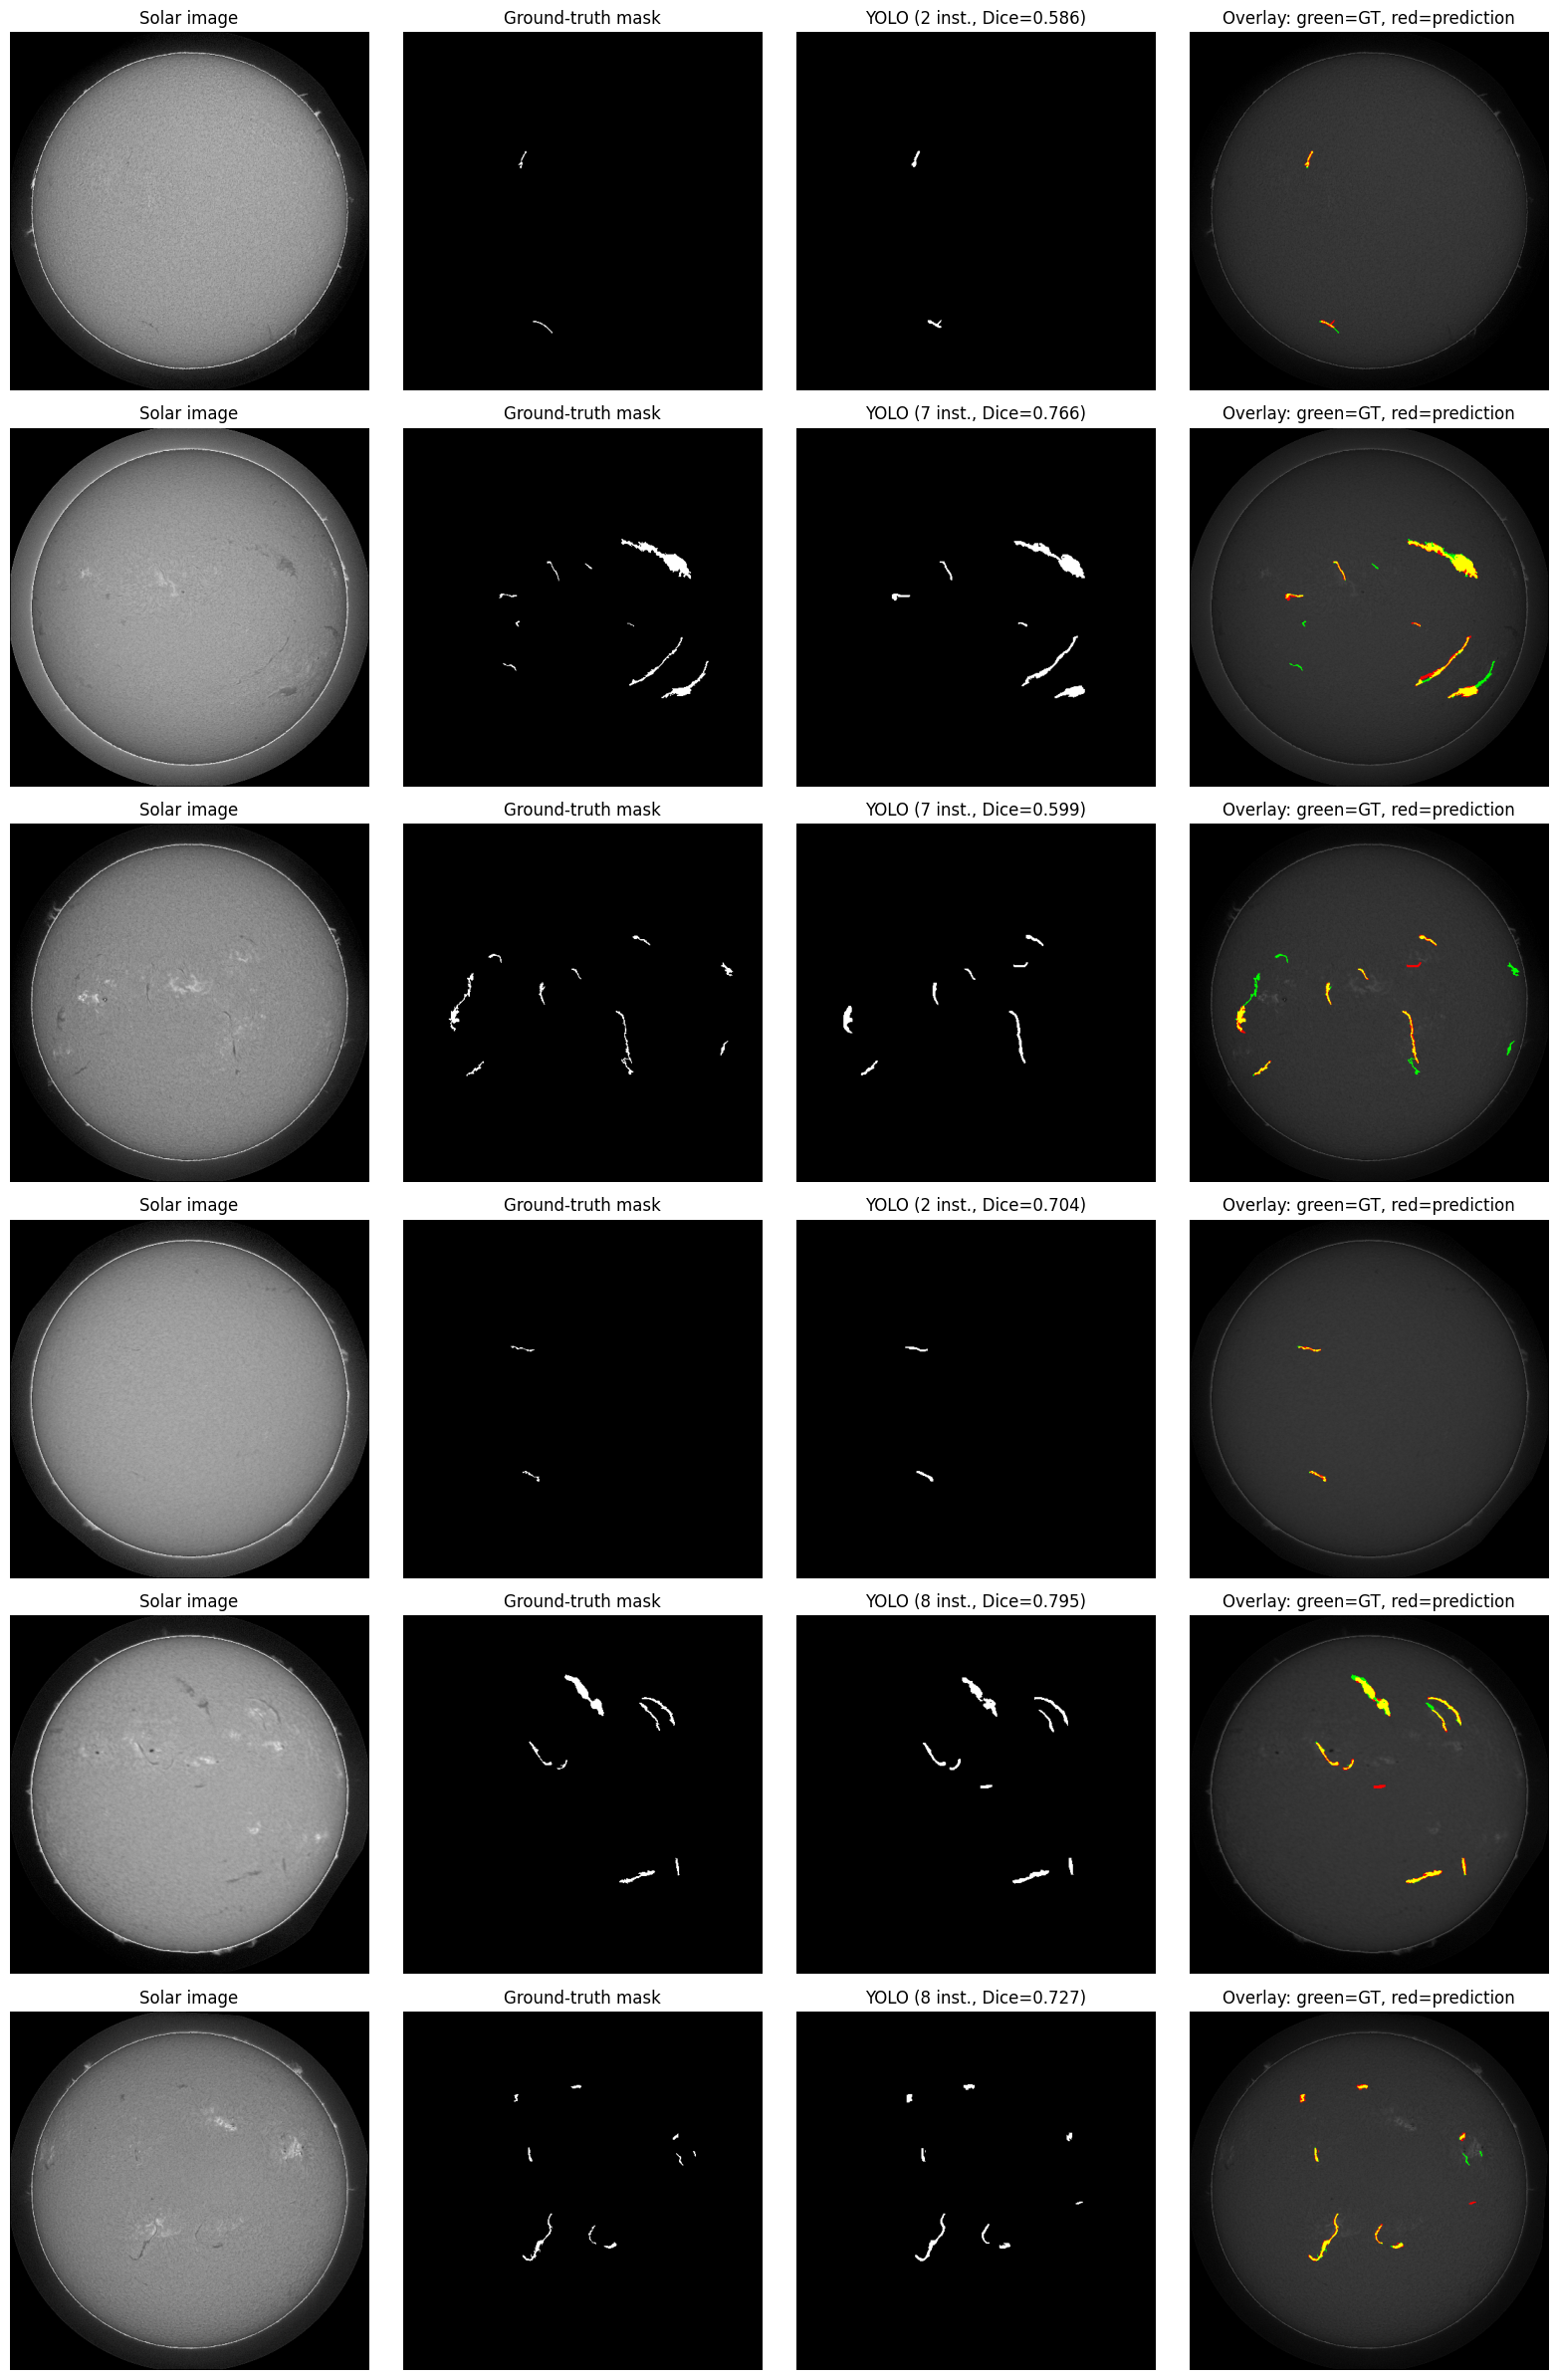

In [10]:
import matplotlib.pyplot as plt
CONF_SHOW = 0.25
sample = random.Random(SEED).sample(val_recs, min(6, len(val_recs)))
fig, axes = plt.subplots(len(sample), 4, figsize=(16, 4 * len(sample)), squeeze=False)
for row, rec in zip(axes, sample):
    img = cv2.resize(cv2.imread(str(IMG_DIR / rec["file_name"]), cv2.IMREAD_GRAYSCALE), (EVAL_SIZE, EVAL_SIZE))
    target = gt_mask(rec); ms, confs = pred_cache[rec["file_name"]]
    keep = confs >= CONF_SHOW
    pred = ms[keep].any(axis=0) if keep.any() else np.zeros_like(target, bool)
    d = metrics(pred, target)[0]
    overlay = np.dstack([img * 0.4] * 3).astype(np.uint8)
    overlay[target.astype(bool)] = [0, 255, 0]; overlay[pred.astype(bool) & ~target.astype(bool)] = [255, 0, 0]
    overlay[pred.astype(bool) & target.astype(bool)] = [255, 255, 0]
    for ax, im, title in zip(row, [img, target, pred, overlay],
                             ["Solar image", "Ground-truth mask", f"YOLO ({keep.sum()} inst., Dice={d:.3f})",
                              "Overlay: green=GT, red=prediction"]):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.savefig(WORK / "yolo_validation_predictions.png", dpi=120); plt.show()

## 9. Save everything for the repo / slides

In [11]:
best_conf = float(summary["mean_dice"].idxmax())
out = {
    "model": MODEL, "imgsz": IMGSZ, "epochs_requested": EPOCHS, "batch": BATCH, "seed": SEED,
    "n_val_records": int(df.record.nunique()),
    "dice_iou_by_conf": summary.reset_index().to_dict(orient="records"),
    "best_conf_by_mean_dice": best_conf,
    "note": "best_conf is chosen on the validation set - report conf=0.25 (YOLO default) as the headline number",
    **yolo_metrics,
}
json.dump(out, open(WORK / "yolo_summary.json", "w"), indent=2)
for f in ["results.png", "results.csv", "MaskPR_curve.png", "confusion_matrix.png"]:
    p = RUN_DIR / f
    if p.exists(): shutil.copy(p, WORK / f"yolo_{f}")
shutil.copy(BEST, WORK / "yolo_best.pt")
print(json.dumps(out, indent=2))
print("\nSaved in", WORK.resolve(), ":", sorted(p.name for p in WORK.glob("yolo_*")))

{
  "model": "yolo11s-seg.pt",
  "imgsz": 1024,
  "epochs_requested": 30,
  "batch": 8,
  "seed": 42,
  "n_val_records": 217,
  "dice_iou_by_conf": [
    {
      "conf": 0.1,
      "mean_dice": 0.6225,
      "median_dice": 0.6506,
      "mean_iou": 0.4633,
      "mean_instances": 15.2396
    },
    {
      "conf": 0.25,
      "mean_dice": 0.65,
      "median_dice": 0.6697,
      "mean_iou": 0.493,
      "mean_instances": 8.2028
    },
    {
      "conf": 0.4,
      "mean_dice": 0.5984,
      "median_dice": 0.6363,
      "mean_iou": 0.449,
      "mean_instances": 5.1659
    },
    {
      "conf": 0.5,
      "mean_dice": 0.5293,
      "median_dice": 0.5833,
      "mean_iou": 0.388,
      "mean_instances": 3.7143
    }
  ],
  "best_conf_by_mean_dice": 0.25,
  "note": "best_conf is chosen on the validation set - report conf=0.25 (YOLO default) as the headline number",
  "box_mAP50": 0.669696971053243,
  "box_mAP50_95": 0.39239339545727414,
  "mask_mAP50": 0.6589295495410865,
  "mask_mAP50_

## 10. Colab only: download the results

In [12]:
if "google.colab" in sys.modules:
    import shutil
    from google.colab import files
    keep = [p for p in WORK.glob("yolo_*") if p.is_file()]
    zip_path = WORK / "yolo_results.zip"
    with zipfile.ZipFile(zip_path, "w") as z:
        for p in keep:
            z.write(p, p.name)
    files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>